Imports

In [85]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

Data Loading

In [86]:
file_path = "QUAC 605 Project Data.xlsx"  # change if needed

df = pd.read_excel(file_path, sheet_name=0)

# Drop useless 'Unnamed' columns (all-NaN or index artifacts)
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

print("Raw shape:", df.shape)
print("Columns:", df.columns.tolist())

# Drop rows where SETTLEMENT_DATE or SETTLEMENT_PERIOD is missing
df = df.dropna(subset=['SETTLEMENT_DATE', 'SETTLEMENT_PERIOD']).copy()

# Convert SETTLEMENT_DATE to datetime
df['SETTLEMENT_DATE'] = pd.to_datetime(df['SETTLEMENT_DATE'])

# 🔴 SAFER: convert SETTLEMENT_PERIOD using Int64 (nullable integer)
df['SETTLEMENT_PERIOD'] = pd.to_numeric(
    df['SETTLEMENT_PERIOD'], errors='coerce'
).astype('Int64')

# If any periods are still NaN after coercion, drop them
df = df.dropna(subset=['SETTLEMENT_PERIOD']).copy()

print("After cleaning date/period:", df.shape)

Raw shape: (14448, 10)
Columns: ['SETTLEMENT_DATE', 'SETTLEMENT_PERIOD', 'ENGLAND_WALES_DEMAND', 'EMBEDDED_WIND_GENERATION', 'EMBEDDED_SOLAR_GENERATION', 'PUMP_STORAGE_PUMPING', 'SCOTTISH_TRANSFER', 'NEMO_FLOW', 'ELECLINK_FLOW', 'Temperature']
After cleaning date/period: (14448, 10)


Build Time Index & Calendar Features

In [87]:
# Each settlement period = 30 minutes. Period 1 -> 00:00
df['datetime'] = df['SETTLEMENT_DATE'] + pd.to_timedelta(
    (df['SETTLEMENT_PERIOD'] - 1).astype(int) * 30,  # cast to plain int *here* only
    unit='m'
)

# Sort by time for time-series consistency
df = df.sort_values('datetime').reset_index(drop=True)

# Calendar features
df['hour'] = df['datetime'].dt.hour
df['day_of_week'] = df['datetime'].dt.dayofweek  # 0=Monday
df['month'] = df['datetime'].dt.month
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)

print(df[['datetime', 'ENGLAND_WALES_DEMAND', 'SETTLEMENT_PERIOD', 'hour']].head())

             datetime  ENGLAND_WALES_DEMAND  SETTLEMENT_PERIOD  hour
0 2025-01-01 00:00:00                 19918                  1     0
1 2025-01-01 00:30:00                 20167                  2     0
2 2025-01-01 01:00:00                 20328                  3     1
3 2025-01-01 01:30:00                 19460                  4     1
4 2025-01-01 02:00:00                 18654                  5     2


Create Lag Features (Core of the Classical Time-Series Model)

In [88]:
target_col = 'ENGLAND_WALES_DEMAND'

# Exogenous variables (adjust if your columns differ)
exog_cols = [
    'Temperature',
    'EMBEDDED_WIND_GENERATION',
    'EMBEDDED_SOLAR_GENERATION',
    'PUMP_STORAGE_PUMPING',
    'SCOTTISH_TRANSFER',
    'NEMO_FLOW',
    'ELECLINK_FLOW'
]

# Fill NaNs in exogenous variables so they don't break lagging
df[exog_cols] = df[exog_cols].fillna(method='ffill').fillna(method='bfill')

# Use past 48 half-hour steps (one full day) of load as inputs
max_lag = 48

# A) Lags of the target
for lag in range(1, max_lag + 1):
    df[f'lag_{lag}'] = df[target_col].shift(lag)

# B) Lag-1 of exogenous variables
for col in exog_cols:
    df[f'{col}_lag1'] = df[col].shift(1)

# C) Build final modeling dataset: drop all rows with any NaNs
df_model = df.dropna().reset_index(drop=True)

print("Shape after lagging & dropping NaNs:", df_model.shape)

Shape after lagging & dropping NaNs: (14400, 70)


C:\Users\Administrator\AppData\Local\Temp\ipykernel_37816\973725670.py:15: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df[exog_cols] = df[exog_cols].fillna(method='ffill').fillna(method='bfill')


Build Feature Matrix X and Target y

In [89]:
feature_cols = []

# 1) Add all load lags
feature_cols += [f'lag_{lag}' for lag in range(1, max_lag + 1)]

# 2) Add exogenous lags
feature_cols += [f'{col}_lag1' for col in exog_cols]

# 3) Add calendar features
feature_cols += ['hour', 'day_of_week', 'month', 'is_weekend']

X = df_model[feature_cols].values
y = df_model[target_col].values

print("Number of features:", X.shape[1])

# Time-based split: 70% train, 15% val, 15% test
n = len(df_model)
train_end = int(n * 0.7)
val_end = int(n * 0.85)

X_train, y_train = X[:train_end], y[:train_end]
X_val,   y_val   = X[train_end:val_end], y[train_end:val_end]
X_test,  y_test  = X[val_end:],          y[val_end:]

time_train = df_model['datetime'].iloc[:train_end]
time_val   = df_model['datetime'].iloc[train_end:val_end]
time_test  = df_model['datetime'].iloc[val_end:]

print("Train size:", X_train.shape)
print("Val size:  ", X_val.shape)
print("Test size: ", X_test.shape)

Number of features: 59
Train size: (10080, 59)
Val size:   (2160, 59)
Test size:  (2160, 59)


Classical Models

4.1 Naive Baseline (Last Value)

In [90]:
# Because df_model already has lag_1 = y_{t-1}, we can just use that.
y_naive_test = df_model['lag_1'].values[val_end:]
y_test_naive_target = y[val_end:]

print("Naive shapes:", y_naive_test.shape, y_test_naive_target.shape)

mae_naive = mean_absolute_error(y_test_naive_target, y_naive_test)
rmse_naive = math.sqrt(mean_squared_error(y_test_naive_target, y_naive_test))

print(f"Naive baseline (lag_1) - MAE: {mae_naive:.2f}, RMSE: {rmse_naive:.2f}")

Naive shapes: (2160,) (2160,)
Naive baseline (lag_1) - MAE: 639.57, RMSE: 830.64


Ridge Regression (Classical Linear Model)

In [91]:
ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0, random_state=42))
])

ridge_model.fit(X_train, y_train)

y_val_pred_ridge = ridge_model.predict(X_val)
y_test_pred_ridge = ridge_model.predict(X_test)

mae_ridge_val = mean_absolute_error(y_val, y_val_pred_ridge)
rmse_ridge_val = math.sqrt(mean_squared_error(y_val, y_val_pred_ridge))

mae_ridge_test = mean_absolute_error(y_test, y_test_pred_ridge)
rmse_ridge_test = math.sqrt(mean_squared_error(y_test, y_test_pred_ridge))

print(f"Ridge - VAL  MAE: {mae_ridge_val:.2f}, RMSE: {rmse_ridge_val:.2f}")
print(f"Ridge - TEST MAE: {mae_ridge_test:.2f}, RMSE: {rmse_ridge_test:.2f}")

Ridge - VAL  MAE: 265.80, RMSE: 346.88
Ridge - TEST MAE: 336.26, RMSE: 434.92


Random Forest (Nonlinear, Strong Classical Baseline)

In [92]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    n_jobs=-1,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_val_pred_rf = rf_model.predict(X_val)
y_test_pred_rf = rf_model.predict(X_test)

mae_rf_val = mean_absolute_error(y_val, y_val_pred_rf)
rmse_rf_val = math.sqrt(mean_squared_error(y_val, y_val_pred_rf))

mae_rf_test = mean_absolute_error(y_test, y_test_pred_rf)
rmse_rf_test = math.sqrt(mean_squared_error(y_test, y_test_pred_rf))

print(f"RandomForest - VAL  MAE: {mae_rf_val:.2f}, RMSE: {rmse_rf_val:.2f}")
print(f"RandomForest - TEST MAE: {mae_rf_test:.2f}, RMSE: {rmse_rf_test:.2f}")

RandomForest - VAL  MAE: 252.19, RMSE: 333.84
RandomForest - TEST MAE: 316.50, RMSE: 420.32


Visualize Predictions vs True Load

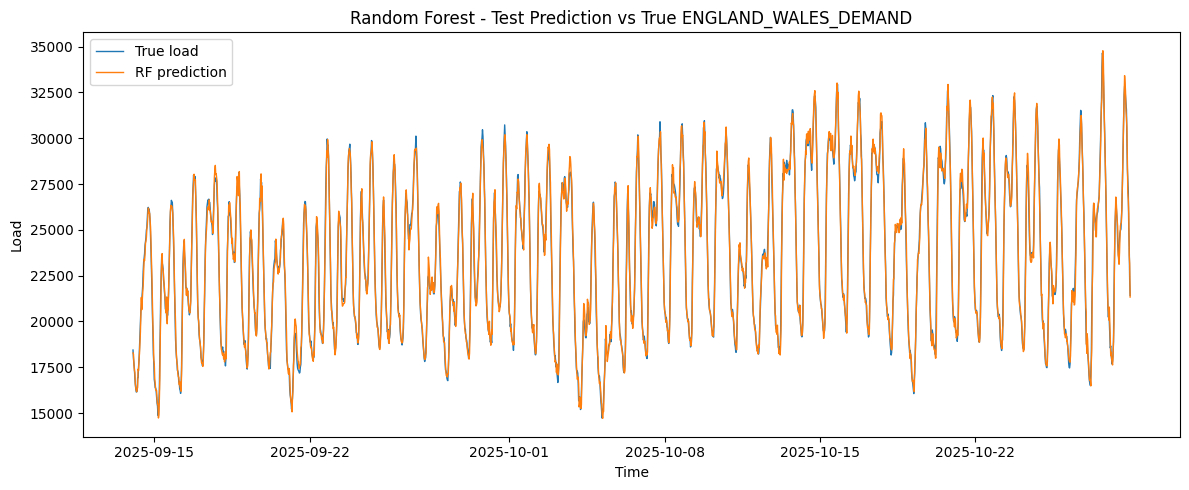

In [93]:
plt.figure(figsize=(12, 5))
plt.plot(time_test, y_test, label="True load", linewidth=1)
plt.plot(time_test, y_test_pred_rf, label="RF prediction", linewidth=1)
plt.title("Random Forest - Test Prediction vs True ENGLAND_WALES_DEMAND")
plt.xlabel("Time")
plt.ylabel("Load")
plt.legend()
plt.tight_layout()
plt.show()
